# Лабораторная работа 5. Решающие деревья и случайный лес

**Версия для студентов: в частях 2–4 нужно дописать по 1–2 строки кода, в части 2 — ещё выбрать глубину дерева.**

**Курс «Машинное обучение», 4 курс** · после лекции 5

**Задача.** Стриминговый сервис (фильмы и сериалы по подписке) теряет подписчиков. Есть 800 подписчиков прошлых месяцев:
сколько смотрят, когда последний раз заходили, тариф, жалобы в поддержку, промокод — и отписались ли они.
Научимся по этим данным угадывать, уйдёт ли **новый** подписчик, — чтобы успеть предложить ему скидку.
Данные выдуманные (их генерирует функция в ноутбуке), но закономерности в них правдоподобные.

**Вопрос занятия:** почему одно глубокое дерево плохо угадывает новых подписчиков, а лес из деревьев — лучше?

| Часть | Тема |
|---|---|
| 1 | Дерево — это цепочка вопросов |
| 2 | Дерево растёт и начинает зубрить |
| 3 | Случайный лес |
| 4 | **Найди ошибку: номер аккаунта** |

Как работать с ноутбуком:

- на **«Подумайте»** сначала ответьте сами, потом запускайте;
- в ячейках **✍ ЗАДАНИЕ** допишите код вместо `...`;
- свёрнутые ячейки достаточно запустить.

In [34]:
# @title Импорты
# Импорты. Эту ячейку достаточно запустить.
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (11, 7.2)
plt.rcParams["figure.dpi"] = 60  # меньше — картинки мельче на экране
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 20
plt.rcParams["axes.titlesize"] = 24
plt.rcParams["axes.labelsize"] = 20
plt.rcParams["legend.fontsize"] = 18

RED, BLUE, ORANGE = "#b2182b", "#2166ac", "#e08214"  # ушёл / остался; кросс-валидация
NODE = LinearSegmentedColormap.from_list("node", ["#92c5de", "#ffffff", "#f4a582"])


def recolor(boxes, model):
    # plot_tree красит «остался» оранжевым; перекрашиваем узлы как точки: голубой — остались, розовый — ушли
    value = model.tree_.value[:, 0, :]
    nodes = [b for b in boxes if "samples" in b.get_text()]   # без подписей True/False у стрелок
    for box, share in zip(nodes, value[:, 1] / value.sum(axis=1)):
        box.set_bbox(dict(boxstyle="round", fc=NODE(share)))

In [35]:
# @title Данные: генератор подписчиков (можно заглянуть)
def make_users(n=800, seed=49):
    # выдуманные подписчики: признаки случайные, уход зависит от них с долей случайности
    rng = np.random.default_rng([7, seed])
    hours = np.round(rng.gamma(2.0, 4.0, n).clip(0, 40), 1)                  # смотрит, часов в неделю
    days = np.round(rng.exponential(6 + 60 / (hours + 3))).clip(0, 60).astype(int)  # дней с последнего входа
    months = rng.integers(1, 37, n)                                          # месяцев с подпиской
    price = rng.choice([199, 299, 499, 799], n, p=[0.3, 0.3, 0.25, 0.15])    # тариф, руб. в месяц
    complaints = rng.poisson(0.8, n).clip(0, 6)                              # обращений в поддержку за месяц
    profiles = rng.integers(1, 6, n)                                         # профилей в аккаунте (семья)
    promo = (rng.random(n) < 0.3).astype(int)                                # пришёл по промокоду
    dark = rng.integers(0, 2, n)                                             # тёмная тема интерфейса
    # что на самом деле влияет на уход (дерево этого не знает); тёмная тема — не влияет
    z = (-0.08 * (hours - 8) - 0.04 * (months - 12) + 0.0015 * (price - 400) + 0.5 * (complaints - 0.8)
         - 0.3 * (profiles - 3) + 0.9 * (promo - 0.3))
    logit = 2.5 * (days >= 14) + 3.0 * z - 1.0
    churned = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)        # 1 — отписался
    user_id = rng.choice(np.arange(100000, 1000000), n, replace=False)      # номер аккаунта
    return pd.DataFrame({"user_id": user_id, "hours": hours, "days": days, "months": months, "price": price,
                         "complaints": complaints, "profiles": profiles, "promo": promo, "dark": dark,
                         "churned": churned})

---
# Часть 1. Дерево — это цепочка вопросов

| столбец | что это |
|---|---|
| `user_id` | номер аккаунта |
| `hours` | смотрит, часов в неделю |
| `days` | дней с последнего входа |
| `months` | сколько месяцев подписан |
| `price` | тариф, руб. в месяц (199, 299, 499, 799) |
| `complaints` | обращений в поддержку за месяц |
| `profiles` | профилей в аккаунте (смотрит вся семья — несколько) |
| `promo` | пришёл по промокоду (1 — да) |
| `dark` | включил тёмную тему (1 — да) |
| `churned` | **отписался** (1 — да) — это и угадываем |

600 подписчиков — для обучения, 200 — **тест**. Тест откроем один раз — в конце части 3.
Номер аккаунта пока уберём из признаков — вернёмся к нему в части 4.

In [36]:
users = make_users()
train, test = train_test_split(users, test_size=0.25, random_state=0, stratify=users["churned"])
X_train, y_train = train.drop(columns=["user_id", "churned"]), train["churned"]
X_test, y_test = test.drop(columns=["user_id", "churned"]), test["churned"]
print("обучение:", len(train), " тест:", len(test), " доля ушедших в обучении:", round(y_train.mean(), 3))
train.head()

обучение: 600  тест: 200  доля ушедших в обучении: 0.403


,user_id,hours,days,months,price,complaints,profiles,promo,dark,churned
229,941088,7.0,0,11,299,0,1,0,0,0
117,169672,7.7,2,1,199,0,4,0,1,0
363,133006,7.0,14,22,199,1,3,0,0,1
488,828238,12.7,3,17,199,0,2,1,1,0
507,385027,3.9,50,6,299,3,3,0,0,1


**Подумайте.** Можно задать о подписчике **один** вопрос. Какой лучше угадает уход:
«не заходил 14 дней и больше?» или «включил тёмную тему?»

In [37]:
for name, question in [("не заходил ≥ 14 дней?", X_train["days"] >= 14), ("тёмная тема?", X_train["dark"] == 1)]:
    print(f"«{name}»   да: ушли {y_train[question].mean():.0%}    нет: ушли {y_train[~question].mean():.0%}")

«не заходил ≥ 14 дней?»   да: ушли 67%    нет: ушли 27%
«тёмная тема?»   да: ушли 42%    нет: ушли 38%


**Что видим.** После вопроса «не заходил ≥ 14 дней?» группы разные: ушли 67% и 27%.
Ответ «да» — скорее уйдёт, «нет» — скорее останется.
После «тёмная тема?» ушли 42% и 38% — почти как во всей выборке (40%). Вопрос почти ничего не сказал.

Хороший вопрос делит подписчиков на группы **почище**: почти все ушли или почти все остались.
Чистоту группы меряет число `gini` (будет на рисунках): 0 — все одного класса, 0.5 — пополам.

![meme_pure](attachment:meme_pure.jpg)

**Решающее дерево** делает то же самое: перебирает все признаки и все пороги
и берёт вопрос «признак ≤ порог?», после которого группы чище всего (`gini` меньше).
В каждой группе ответ — **большинство**: ушло больше половины — «уйдёт».

Дерево с одним вопросом — **глубины 1** (`max_depth=1`). Какой вопрос оно выберет?

In [38]:
stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_train, y_train)
print("доля верных на обучении:", round(stump.score(X_train, y_train), 3))

доля верных на обучении: 0.712


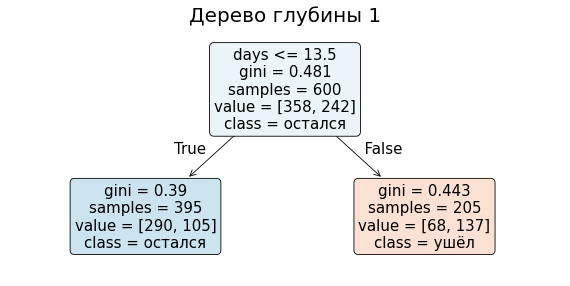

In [39]:
# @title Рисунок: дерево глубины 1
plt.figure(figsize=(12, 5.5))
boxes = plot_tree(stump, feature_names=list(X_train.columns), class_names=["остался", "ушёл"],
                  filled=True, fontsize=18)
recolor(boxes, stump)
for box in boxes:
    box.set_text(re.sub(r"(\d+)\.0(?=[,\]])", r"\1", box.get_text()))   # «290.0» → «290»
plt.title("Дерево глубины 1")
plt.show()

**Что видим.**

- Из восьми признаков дерево само выбрало дни без входа: вопрос `days <= 13.5` — «заходил в последние 13 дней?». Порог 13.5 — между 13 и 14.
- Налево (да) — 395 подписчиков, ответ «остался»; направо — 205, ответ «ушёл». В строке `value` — сколько оставшихся и ушедших.
- Доля верных на обучении: (290 + 137) / 600 = 0.712 — слева верны 290 оставшихся, справа 137 ушедших, делим на всех 600. Одно правило уже угадывает больше двух третей подписчиков.
  Для сравнения: ответ «все останутся» без всяких вопросов угадывает 0.597 — столько подписчиков остались.
- **Gini** узла = 1 − (доля одного класса)² − (доля другого)². Он равен 0, если в узле один класс, и 0.5, если классы поровну: чем меньше, тем чище.
  Корень: 1 − 0.597² − 0.403² ≈ 0.481. Налево (395; 290 и 105): 1 − 0.734² − 0.266² ≈ 0.390. Направо (205; 68 и 137): 1 − 0.332² − 0.668² ≈ 0.443.
  Дерево берёт вопрос, у которого средний gini после разбиения (с весами по числу людей) меньше всего: (395 · 0.390 + 205 · 0.443) / 600 ≈ 0.409 — это меньше 0.481.

![meme_rule_tree](attachment:meme_rule_tree.jpg)

Дальше то же самое повторяется **в каждой группе**: дерево ищет там свой лучший вопрос. Получается дерево глубины 2.

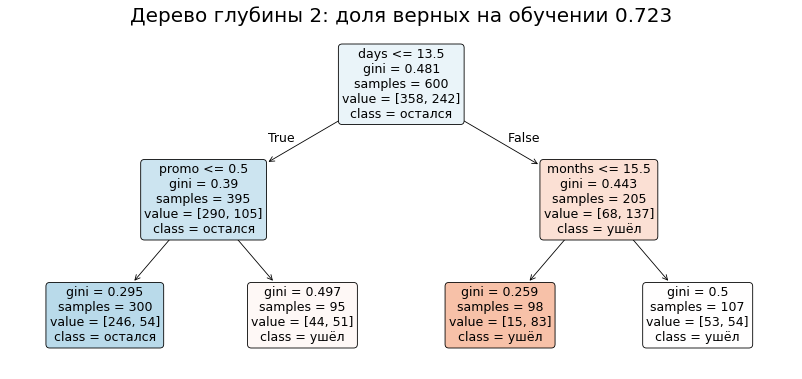

In [40]:
# @title Рисунок: дерево глубины 2
tree2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train, y_train)
plt.figure(figsize=(17, 7.5))
boxes = plot_tree(tree2, feature_names=list(X_train.columns), class_names=["остался", "ушёл"],
                  filled=True, fontsize=15)
recolor(boxes, tree2)
for box in boxes:
    box.set_text(re.sub(r"(\d+)\.0(?=[,\]])", r"\1", box.get_text()))   # «51.0» → «51»
plt.title(f"Дерево глубины 2: доля верных на обучении {tree2.score(X_train, y_train):.3f}")
plt.show()

**Что видим.** Дерево читается как правила:

- заходил недавно и пришёл без промокода — ушли 18% (300 человек);
- заходил недавно, но пришёл по промокоду — уже 54%: подписались ради скидки и уходят, когда она кончается;
- не заходил две недели и подписан до 15 месяцев — ушли 85%;
- не заходил две недели, но подписан дольше — только 50%: старых подписчиков пауза пугает меньше.

В каждой группе дерево нашло **свой** второй вопрос: слева про промокод, справа про стаж подписки.
Справа оба листа отвечают «ушёл» (85% и 50%): второй вопрос ответа не меняет, а только отделяет почти наверняка ушедших от сомнительных.
Поэтому доля верных на обучении выросла лишь до 0.723.

---
# Часть 2. Дерево растёт и начинает зубрить

Дальше дерево снова и снова ищет вопрос в каждой новой группе. Без ограничения глубины оно растёт,
пока в каждом листе не останутся подписчики одного класса — иногда один человек.

**Подумайте.** Что будет с долей верных на обучении при глубине 2, 4, 8 и без ограничения? А на новых подписчиках?

Новых подписчиков у нас нет, а тест трогать рано. Поэтому используем **кросс-валидацию** (лекция 4):
делим 600 подписчиков на 5 блоков, обучаем на четырёх, проверяем на пятом — и так 5 раз, чтобы каждый блок побыл проверочным.
Каждого подписчика проверяет модель, которая его не видела. Итог — среднее пяти долей верных.

Блоки задаёт `cv5` (одинаковые у всех), весь цикл делает `cross_val_score`.

![pic_kfold](attachment:pic_kfold.jpg)

In [41]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)   # 5 блоков, номера перемешаны
scores = cross_val_score(DecisionTreeClassifier(max_depth=1, random_state=0), X_train, y_train, cv=cv5)
print("дерево глубины 1, доля верных по блокам:", scores.round(3), " среднее:", round(scores.mean(), 3))

дерево глубины 1, доля верных по блокам: [0.725 0.642 0.767 0.75  0.675]  среднее: 0.712


**Что видим.** На пяти блоках доля верных от 0.642 до 0.767, среднее 0.712.
Одна проверка могла дать любое из этих чисел, поэтому берём среднее.

**✍ Задание.** Допишите цикл: для каждой глубины — доля верных по кросс-валидации и на обучении.

In [42]:
# ✍ ЗАДАНИЕ НА СЕМИНАРЕ: доля верных для разных глубин
rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 12, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=0)
    cv = cross_val_score(model, X_train, y_train, cv = cv5).mean()   # средняя доля верных по кросс-валидации cv5 (как в ячейке с cv5 выше)
    model.fit(X_train, y_train)
    acc = model.score(X_train, y_train)   # доля верных на тех же данных, на которых обучали
    rows.append([str(depth), model.get_n_leaves(), acc, cv])
by_depth = pd.DataFrame(rows, columns=["глубина", "листьев", "обучение", "кросс-вал."])
by_depth.round(3)

,глубина,листьев,обучение,кросс-вал.
0,1,2,0.712,0.712
1,2,4,0.723,0.693
2,3,8,0.788,0.732
3,4,15,0.833,0.755
4,5,27,0.868,0.775
5,6,45,0.895,0.760
6,8,81,0.955,0.758
7,10,98,0.990,0.757
8,12,104,1.000,0.748
9,None,104,1.000,0.738


In [43]:
# Проверка. Не меняйте эту ячейку.
ref = pd.DataFrame({
    "глубина": ['1', '2', '3', '4', '5', '6', '8', '10', '12', 'None'],
    "листьев": [2, 4, 8, 15, 27, 45, 81, 98, 104, 104],
    "обучение": [0.712, 0.723, 0.788, 0.833, 0.868, 0.895, 0.955, 0.99, 1.0, 1.0],
    "кросс-вал.": [0.712, 0.693, 0.732, 0.755, 0.775, 0.76, 0.758, 0.757, 0.748, 0.738],
})
try:
    ok = bool(np.allclose(by_depth[["обучение", "кросс-вал."]].astype(float), ref[["обучение", "кросс-вал."]], atol=6e-4))
    print("верно" if ok else "НЕ совпало: проверьте, на каких данных считается каждая доля")
except Exception as e:
    print("цикл ещё не готов:", type(e).__name__)
    ok = False
if not ok:
    by_depth = ref   # дальше ноутбук идёт на эталоне

верно


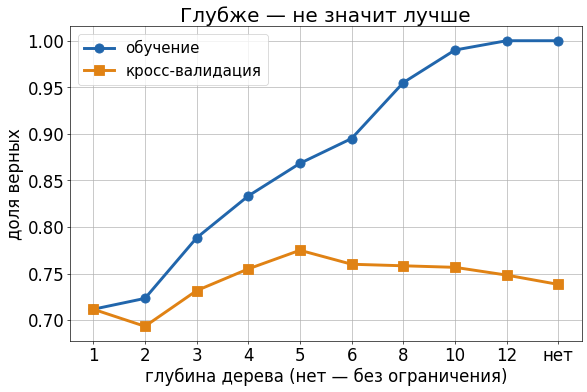

In [44]:
# @title Рисунок: доля верных от глубины
plt.figure(figsize=(11, 6.8))
pos = np.arange(len(by_depth))
plt.plot(pos, by_depth["обучение"], "o-", c=BLUE, lw=3.5, ms=11, label="обучение")
plt.plot(pos, by_depth["кросс-вал."], "s-", c=ORANGE, lw=3.5, ms=11, label="кросс-валидация")
plt.xticks(pos, [d if d != "None" else "нет" for d in by_depth["глубина"]])
plt.xlabel("глубина дерева (нет — без ограничения)")
plt.ylabel("доля верных")
plt.title("Глубже — не значит лучше")
plt.legend()
plt.show()

**✍ Задание.** Какую глубину выбрать для новых подписчиков? Впишите её по таблице или рисунку.
И одной фразой: почему не 12 — ведь на обучении там 1.0?

In [45]:
best_depth = 5   # ✍ глубина дерева — число
# ✍ Почему не 12: ...

In [46]:
# Проверка. Не меняйте эту ячейку.
best = by_depth.loc[by_depth["кросс-вал."].astype(float).idxmax(), "глубина"]
if best_depth is ...:
    print("впишите best_depth")
elif str(best_depth) == best:
    print("верно")
else:
    print("НЕ совпало: какая доля говорит о новых подписчиках — на обучении или по кросс-валидации?")

верно


**Что видим.**

- На обучении доля верных только растёт: от 0.712 до 1.0 без ограничения. Там 104 листа на 600 подписчиков — в среднем 6 человек в листе.
- По кросс-валидации лучше всего глубина 5 (0.775). Дальше доля падает: без ограничения 0.738.
- Глубина 2 по кросс-валидации даже чуть хуже глубины 1 (0.693 против 0.712). Разница — 11 подписчиков из 600: на других блоках могло выйти наоборот.

Глубокое дерево **зубрит**: запоминает обучающих подписчиков, а новых угадывает хуже. Это переобучение.
Глубину выбирают по кросс-валидации — здесь 5.

![meme_cram](attachment:meme_cram.jpg)

Как выглядит зубрёжка? Возьмём только два признака — стаж подписки и часы просмотра —
и закрасим, где дерево отвечает «уйдёт» (розовым) и «останется» (голубым).

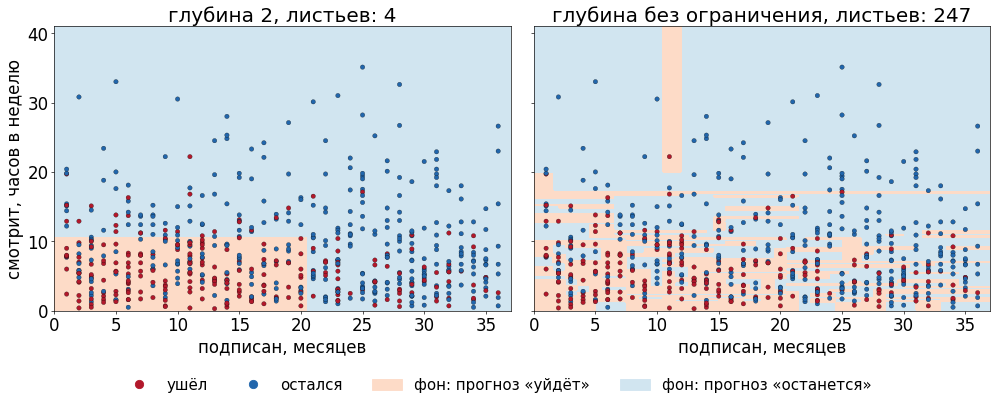

In [47]:
# @title Рисунок: дерево на двух признаках — глубина 2 и без ограничения
X2 = X_train[["months", "hours"]]
mm, hh = np.meshgrid(np.linspace(0, 37, 300), np.linspace(0, 41, 300))
grid = pd.DataFrame({"months": mm.ravel(), "hours": hh.ravel()})
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True)
for ax, depth in zip(axes, [2, None]):
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X2, y_train)
    zz = t.predict(grid).reshape(mm.shape)
    ax.contourf(mm, hh, zz, levels=[-0.5, 0.5, 1.5], colors=["#d1e5f0", "#fddbc7"])
    ax.scatter(X2["months"], X2["hours"], c=np.where(y_train == 1, RED, BLUE), s=28,
               edgecolors="k", linewidths=0.3)
    ax.set_title(f"глубина {depth or 'без ограничения'}, листьев: {t.get_n_leaves()}")
    ax.set_xlabel("подписан, месяцев")
    ax.grid(False)
axes[0].set_ylabel("смотрит, часов в неделю")
fig.legend(handles=[Line2D([], [], marker="o", ls="", ms=10, c=RED, label="ушёл"),
                    Line2D([], [], marker="o", ls="", ms=10, c=BLUE, label="остался"),
                    Patch(color="#fddbc7", label="фон: прогноз «уйдёт»"),
                    Patch(color="#d1e5f0", label="фон: прогноз «останется»")],
           loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

**Что видим.**

- Граница дерева — **ступеньки**: каждый вопрос «признак ≤ порог?» режет плоскость вертикальной или горизонтальной прямой.
- Глубина 2 — четыре прямоугольника, но закономерность одна и крупная: подписан меньше 21 месяца и смотрит меньше 11 часов в неделю — «уйдёт», остальное — «останется».
- Без ограничения — мозаика из мелких клеток вокруг отдельных подписчиков: дерево выучило их наизусть. Это переобучение.

---
# Часть 3. Случайный лес

Глубокое дерево ещё и **неустойчиво**: чуть другие обучающие подписчики — и нижние вопросы совсем другие.
Проверим. Новых подписчиков взять негде, поэтому сделаем «другую выборку» из тех же:
вытянем 600 номеров **с возвращением** — это **бутстреп**. Кто-то попадёт дважды или трижды, кто-то ни разу.

Каждое дерево получает свою выборку: кого-то дважды, кого-то ни разу. Поэтому деревья выходят разными.

![pic_bootstrap](attachment:pic_bootstrap.jpg)

In [48]:
rng = np.random.default_rng(0)
idx = rng.integers(0, len(X_train), len(X_train))      # 600 случайных номеров с возвращением
times = np.bincount(idx, minlength=len(X_train))       # сколько раз выбран каждый подписчик
print("выбран k раз → подписчиков:", dict(enumerate(np.bincount(times).tolist())))
print("не попали ни разу:", round(np.mean(times == 0), 3))

выбран k раз → подписчиков: {0: 223, 1: 216, 2: 112, 3: 38, 4: 9, 5: 2}
не попали ни разу: 0.372


**Что видим.** 223 подписчика (37%) не попали ни разу, 112 выбраны дважды, двое — пять раз.
В среднем не попадает около 37%: каждая бутстреп-выборка немного другая.

**Подумайте.** Обучим два глубоких дерева на двух бутстреп-выборках (снова только стаж подписки и часы просмотра). Похожи ли будут их ответы?

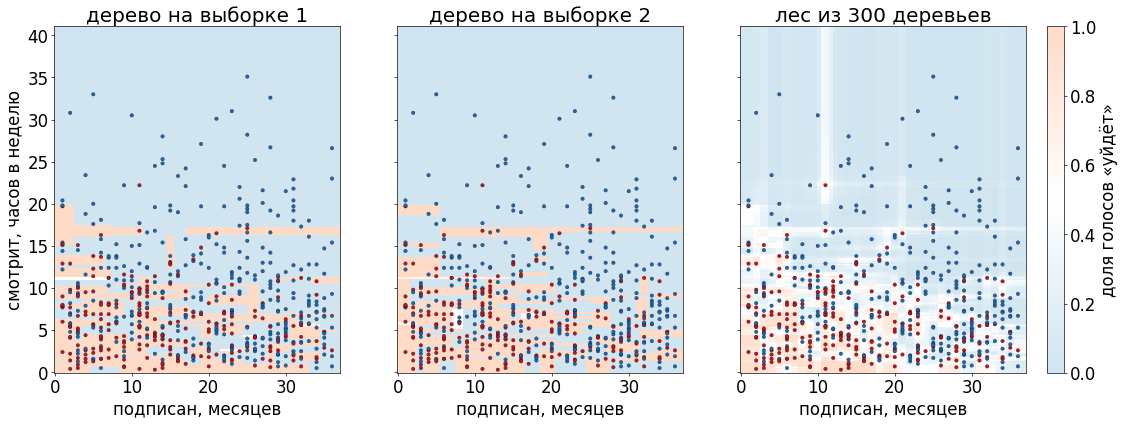

In [49]:
# @title Рисунок: два дерева на разных выборках и лес
from matplotlib.colors import LinearSegmentedColormap
boot = np.random.default_rng(0)
panels = []
for k in [1, 2]:
    i = boot.integers(0, len(X2), len(X2))                  # бутстреп-выборка
    panels.append((f"дерево на выборке {k}", DecisionTreeClassifier(random_state=0).fit(X2.iloc[i], y_train.iloc[i])))
panels.append(("лес из 300 деревьев", RandomForestClassifier(n_estimators=300, random_state=0).fit(X2, y_train)))
PALE = LinearSegmentedColormap.from_list("pale", ["#d1e5f0", "#ffffff", "#fddbc7"])  # цвета как на мозаике выше
fig, axes = plt.subplots(1, 3, figsize=(22, 7.5), sharey=True)
for ax, (title, m) in zip(axes, panels):
    vote = m.predict_proba(grid)[:, 1].reshape(mm.shape)   # доля голосов «уйдёт»; у одного дерева почти всегда 0 или 1
    mesh = ax.pcolormesh(mm, hh, vote, cmap=PALE, vmin=0, vmax=1, shading="auto")
    ax.scatter(X2["months"], X2["hours"], c=np.where(y_train == 1, RED, BLUE), s=18,
               edgecolors="k", linewidths=0.3)
    ax.set_title(title)
    ax.set_xlabel("подписан, месяцев")
    ax.grid(False)
axes[0].set_ylabel("смотрит, часов в неделю")
fig.colorbar(mesh, ax=axes, fraction=0.03, pad=0.02, label="доля голосов «уйдёт»")
plt.show()

**Что видим.**

- Два дерева выучили каждое свою мозаику: на одних и тех же (стаж, часы) они отвечают по-разному на 13% рисунка.
  Какой из мозаик верить?
- Лес обучает сотни таких деревьев и **голосует**. Где деревья согласны — цвет яркий, где спорят — бледный.
  Случайные клетки отдельных деревьев при голосовании гасят друг друга.

![meme_forest](attachment:meme_forest.jpg)

**Случайный лес** — много деревьев, каждое на своей бутстреп-выборке. Вдобавок в каждом узле дерево выбирает вопрос
не из всех 8 признаков, а из 2 случайных — так деревья получаются ещё непохожее друг на друга. Ответ леса — голосование деревьев.

**Подумайте.** Как изменится доля верных по кросс-валидации для 1, 3, 10, 30, 100, 300 деревьев? Переобучится ли лес из 300 деревьев?

In [ ]:
# ✍ ЗАДАНИЕ НА СЕМИНАРЕ: лес из разного числа деревьев
rows = []
for n_trees in [1, 3, 10, 30, 100, 300]:
    forest = RandomForestClassifier(n_estimators=n_trees, random_state=0)
    cv = cross_val_score(forest, X_train, y_train, cv = cv5).mean()   # как в части 2: средняя доля верных леса по кросс-валидации
    rows.append([n_trees, cv])
by_trees = pd.DataFrame(rows, columns=["деревьев", "кросс-вал."])
by_trees.round(3)

In [ ]:
# Проверка. Не меняйте эту ячейку.
ref = pd.DataFrame({
    "деревьев": [1, 3, 10, 30, 100, 300],
    "кросс-вал.": [0.75, 0.752, 0.773, 0.802, 0.822, 0.83],
})
try:
    ok = bool(np.allclose(by_trees["кросс-вал."].astype(float), ref["кросс-вал."], atol=6e-4))
    print("верно" if ok else "НЕ совпало")
except Exception as e:
    print("цикл ещё не готов:", type(e).__name__)
    ok = False
if not ok:
    by_trees = ref   # дальше ноутбук идёт на эталоне

In [ ]:
# @title Рисунок: лес — доля верных от числа деревьев
plt.figure(figsize=(11, 6.8))
plt.plot(by_trees["деревьев"], by_trees["кросс-вал."], "s-", c=ORANGE, lw=3.5, ms=11, label="лес, кросс-валидация")
plt.axhline(by_depth["кросс-вал."].iloc[-1], c="k", ls=":", lw=3, label="одно дерево без ограничения")
plt.xscale("log")
plt.xticks(by_trees["деревьев"], by_trees["деревьев"])
plt.minorticks_off()
plt.xlabel("число деревьев (лог. шкала)")
plt.ylabel("доля верных")
plt.title("Больше деревьев — выход на плато")
plt.legend()
plt.show()

**Что видим.**

- Одно дерево леса — 0.750, примерно как обычное дерево без ограничения (0.738): оно тоже глубокое и тоже зубрит.
- 10 деревьев — 0.773, 100 — 0.822, 300 — 0.830: качество растёт и выходит на плато.
- От числа деревьев лес не переобучается: новое дерево только уточняет голосование. Переобучаются сами деревья, а не их число.

![meme_forest_size](attachment:meme_forest_size.jpg)

**Итог: три модели.** Дерево глубины 1 (один вопрос), дерево глубины 5 (лучшее по кросс-валидации в части 2) и лес из 300 деревьев.
Выбираем по кросс-валидации, тест пока не трогаем.

In [ ]:
models = {
    "дерево глубины 1": DecisionTreeClassifier(max_depth=1, random_state=0),
    "дерево глубины 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "лес, 300 деревьев": RandomForestClassifier(n_estimators=300, random_state=0),
}
cv_score = {name: cross_val_score(model, X_train, y_train, cv=cv5).mean() for name, model in models.items()}
pd.Series(cv_score, name="кросс-вал.").round(3)

**Что видим.** Лес — 0.830, дерево глубины 5 — 0.775, один вопрос — 0.712.
Лес лучше лучшего дерева на 0.055 — это 33 подписчика из 600. Выбираем лес.

**Тест — один раз.** Обучаем все три модели на 600 подписчиках и считаем долю верных на 200 тестовых.
По тесту ничего не выбираем: выбор уже сделан по кросс-валидации.

In [ ]:
test_score = {name: model.fit(X_train, y_train).score(X_test, y_test) for name, model in models.items()}
final = pd.DataFrame({"кросс-вал.": cv_score, "тест": test_score})
final.round(3)

**Что видим.**

- Лес на тесте — 0.860, дерево глубины 5 — 0.750, один вопрос — 0.630. Порядок тот же, что по кросс-валидации.
  Ответ «все останутся» на тесте — 0.600: один вопрос (0.630) лишь чуть лучше него.
- Сами числа от кросс-валидации отличаются в обе стороны: у леса +0.03, у одного вопроса −0.08. Один подписчик теста — это 0.005,
  а 200 человек — мало: на другом тесте вышло бы немного иначе. Перевыбирать модель по тесту нельзя: это подгонка под 200 человек.

---
# Часть 4. Найди ошибку: номер аккаунта

У леса есть готовая «важность признаков» `feature_importances_`: насколько вопросы по признаку очистили группы
(уменьшили `gini`) во всех деревьях леса; доли, в сумме 1.

Коллега вернул в данные **номер аккаунта** и посмотрел важности.

**Подумайте.** Какое место займёт номер аккаунта?

In [ ]:
# Код коллеги.
X_id = X_train.assign(user_id=train["user_id"])   # вернули номер аккаунта
forest_id = RandomForestClassifier(n_estimators=300, random_state=0).fit(X_id, y_train)
importance = pd.Series(forest_id.feature_importances_, index=X_id.columns)
importance.sort_values(ascending=False).round(3)

Вывод коллеги: «Номер аккаунта — на четвёртом месте (0.109), важнее жалоб (0.092), промокода (0.079) и тарифа.
Значит, номер аккаунта влияет на уход — оставлю его в модели.»

**Найдите ошибку.** Чему верить — важности леса или здравому смыслу?

Проверим на данных, которых лес не видел. Отложим 30% обучения (тест по-прежнему не трогаем), обучим лес с номером на остальных 70%
и **перемешаем** каждый столбец по очереди на отложенной части. Если признак полезен, доля верных упадёт; если нет — не изменится.
Это `permutation_importance`: среднее падение доли верных по 10 перемешиваниям.

In [ ]:
X_fit, X_val, y_fit, y_val = train_test_split(X_id, y_train, test_size=0.3, random_state=0, stratify=y_train)
forest_val = RandomForestClassifier(n_estimators=300, random_state=0).fit(X_fit, y_fit)
perm = permutation_importance(forest_val, X_val, y_val, n_repeats=10, random_state=0)
compare = pd.DataFrame({"по Джини (обучение)": forest_val.feature_importances_,
                        "перемешивание (отложенные)": perm.importances_mean}, index=X_id.columns)
compare.sort_values("перемешивание (отложенные)", ascending=False).round(3)

In [ ]:
# @title Рисунок: важность по Джини и перемешиванием
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, col, xlabel in zip(axes, compare.columns, ["уменьшение gini", "падение доли верных"]):
    imp = compare[col].sort_values()
    ax.barh(imp.index, imp.values, color=[RED if f == "user_id" else "#999999" for f in imp.index])
    ax.set_title(col)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Что видим.**

- Номер аккаунта (красный) по Джини на четвёртом месте, а по перемешиванию — последний.
- По перемешиванию номер бесполезен: 0.004, доля верных почти не меняется. По Джини у этого же леса он 0.114 — выше жалоб, промокода и тарифа.
- Первые по перемешиванию — стаж, дни без входа и часы просмотра (около 0.09). Промокод по Джини выглядит слабым — 0.074, меньше половины часов (0.187),
  а по перемешиванию почти вровень с ними (0.072 против 0.081): у промокода всего два значения, и Джини его недооценивает.

Может, номер всё-таки что-то значит? Раздадим номера заново, случайно, и посмотрим на важность по Джини.

In [ ]:
shuffled_id = np.random.default_rng(0).permutation(train["user_id"].values)   # те же номера, раздали случайно
X_rand = X_train.assign(user_id=shuffled_id)
forest_rand = RandomForestClassifier(n_estimators=300, random_state=0).fit(X_rand, y_train)
print("важность номера по Джини: настоящий", round(importance["user_id"], 3),
      "  случайный", round(forest_rand.feature_importances_[-1], 3))

**Что видим.** Случайным номерам лес дал почти ту же важность: 0.109 и 0.105. Высокая важность номера — свойство подсчёта по Джини, а не связь с уходом:
по признаку с сотнями разных значений глубокие деревья всегда найдут, кого от кого отделить.

**Правило:** важность по Джини рассказывает, как лес устроен на обучающих данных, а не что помогает на новых.
Признаки-идентификаторы (номер аккаунта, телефон, e-mail) в модель не кладут, а важность проверяют перемешиванием на отложенных данных.

**✍ Задание.** Последний довод для коллеги: помогает ли номер угадывать **новых** подписчиков?
Посчитайте долю верных по кросс-валидации `cv5` у леса коллеги (300 деревьев, `random_state=0`) с номером (`X_id`) и без него (`X_train`).

![meme_id](attachment:meme_id.jpg)

In [ ]:
# ✍ ЗАДАНИЕ НА СЕМИНАРЕ: лес с номером аккаунта и без
forest = RandomForestClassifier(n_estimators=300, random_state=0)
cv_with_id = cross_val_score(forest, X_id, y_train, cv = cv5).mean()      # с номером
cv_without_id = cross_val_score(forest, X_train, y_train, cv = cv5).mean()   # без номера
if cv_without_id is not ...:
    print("с номером:", round(cv_with_id, 3), " без номера:", round(cv_without_id, 3))

In [ ]:
# Проверка. Не меняйте эту ячейку.
try:
    ok = bool(np.allclose([cv_with_id, cv_without_id], [0.818, 0.830], atol=6e-4))
    print("верно" if ok else "НЕ совпало: проверьте, на каких данных обучается каждый лес")
except Exception as e:
    print("ещё не готово:", type(e).__name__)

**Что видим.** С номером доля верных даже ниже: 0.818 против 0.830 без него. Номер не помогает, а мешает:
часть вопросов деревья тратят на запоминание отдельных подписчиков. Вывод коллеги неверен — номер из модели убираем.

---
# Что запомнить

- Решающее дерево — цепочка вопросов «признак ≤ порог?»; ответ в листе — большинство.
- Вопрос выбирают так, чтобы группы после него стали чище (`gini` меньше): «не заходил ≥ 14 дней?» — хороший вопрос, «тёмная тема?» — бесполезный.
- Глубокое дерево зубрит: без ограничения 1.0 на обучении и 0.738 по кросс-валидации. Глубину выбирают по кросс-валидации.
- Деревья на чуть разных выборках получаются разными. Лес обучает много таких деревьев и голосует:
  случайные ошибки гасятся, а с ростом числа деревьев качество выходит на плато, а не переобучается.
- Тест — один раз в конце. 200 человек — мало, разница в несколько процентов — шум.
- Важность признаков у леса завышает признаки с множеством значений (даже номер аккаунта);
  полезность признака проверяют перемешиванием на отложенных данных.

---
# Домашняя работа 5

**Банк просит модель для выдачи кредитов.** У каждого свои 800 прошлых заявок (по фамилии): доход, сумма, платёж, другие кредиты, просрочки, залог…
Нужно прочитать правило выдачи из дерева глубины 2, выбрать модель по кросс-валидации (лучшее дерево или лес)
и найти, откуда у стажёра 98% (утечка из будущего). Дополнительно, по желанию: объяснить клиенту, почему ему отказали,
и сверить всё с формулой, по которой данные сгенерированы.